Saving Tweets.csv to Tweets (4).csv
(14640, 15)
tweet_id                          int64
airline_sentiment                object
airline_sentiment_confidence    float64
negativereason                   object
negativereason_confidence       float64
airline                          object
airline_sentiment_gold           object
name                             object
negativereason_gold              object
retweet_count                     int64
text                             object
tweet_coord                      object
tweet_created                    object
tweet_location                   object
user_timezone                    object
dtype: object
             tweet_id airline_sentiment  airline_sentiment_confidence  \
0  570306133677760513           neutral                        1.0000   
1  570301130888122368          positive                        0.3486   
2  570301083672813571           neutral                        0.6837   
3  570301031407624196          negative       

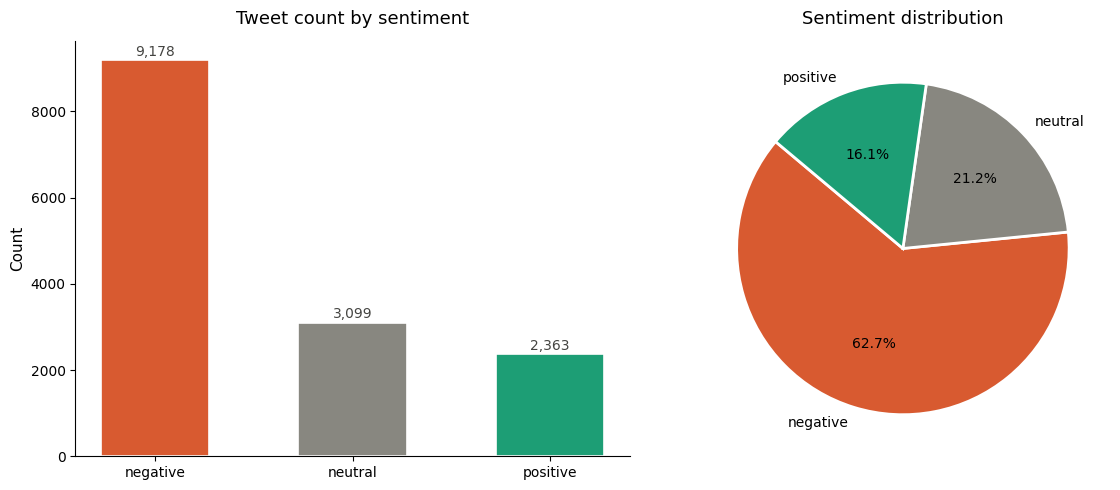

negativereason
Customer Service Issue         2910
Late Flight                    1665
Can't Tell                     1190
Cancelled Flight                847
Lost Luggage                    724
Bad Flight                      580
Flight Booking Problems         529
Flight Attendant Complaints     481
longlines                       178
Damaged Luggage                  74
Name: count, dtype: int64


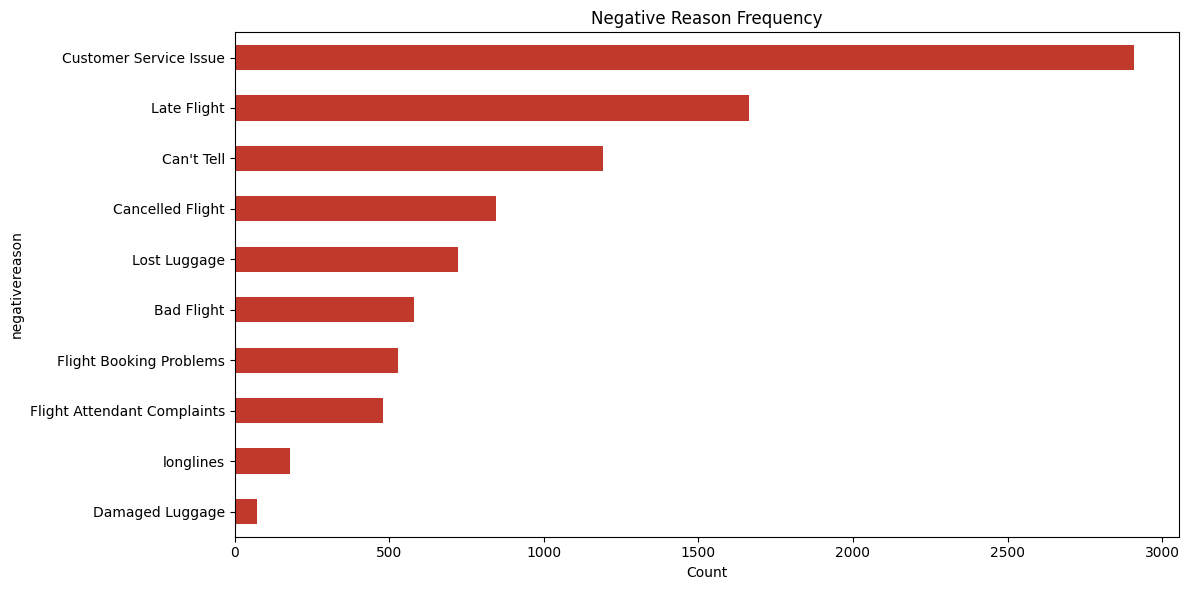

airline_sentiment  negative  neutral  positive
airline                                       
American               1960      463       336
Delta                   955      723       544
Southwest              1186      664       570
US Airways             2263      381       269
United                 2633      697       492
Virgin America          181      171       152


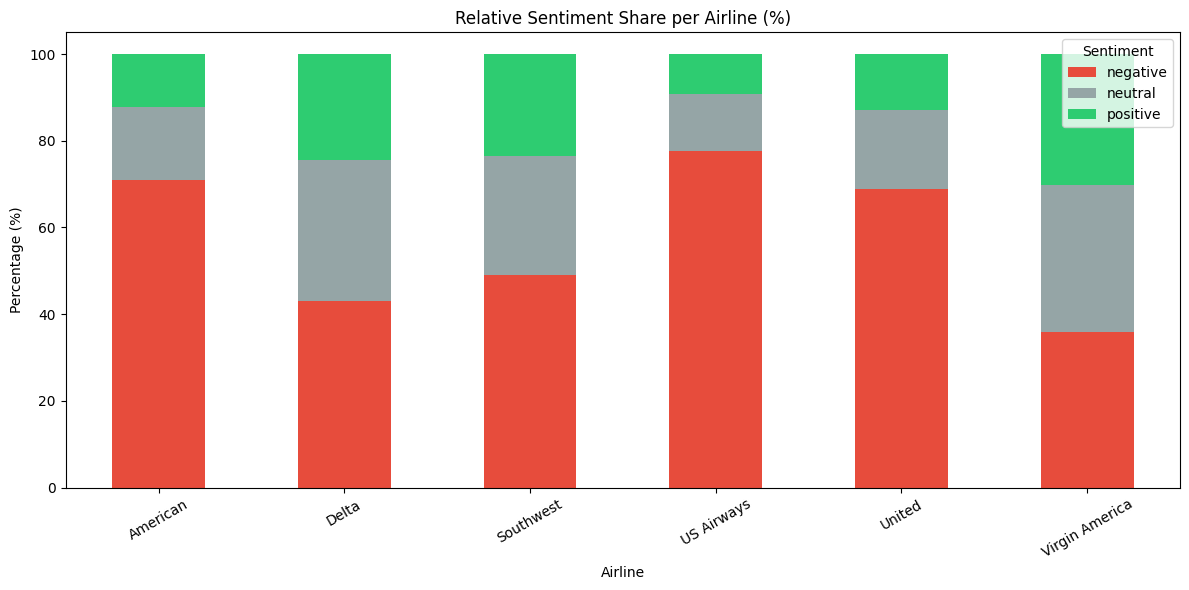

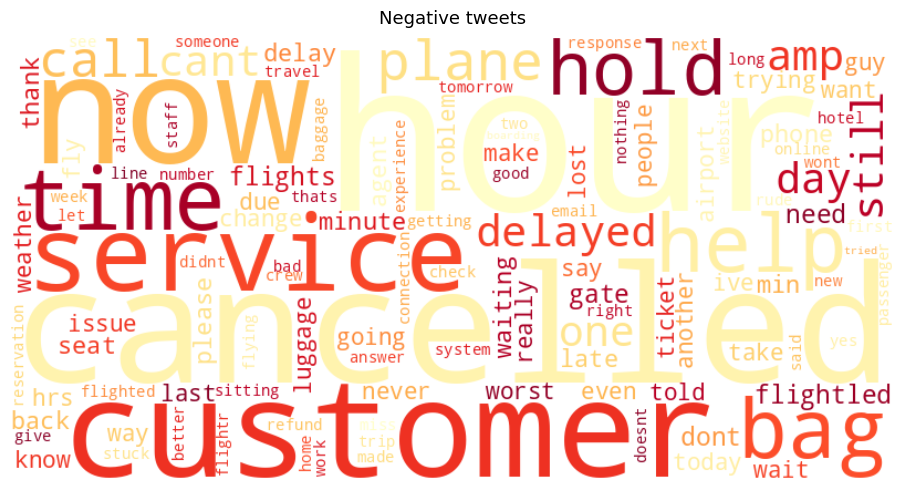

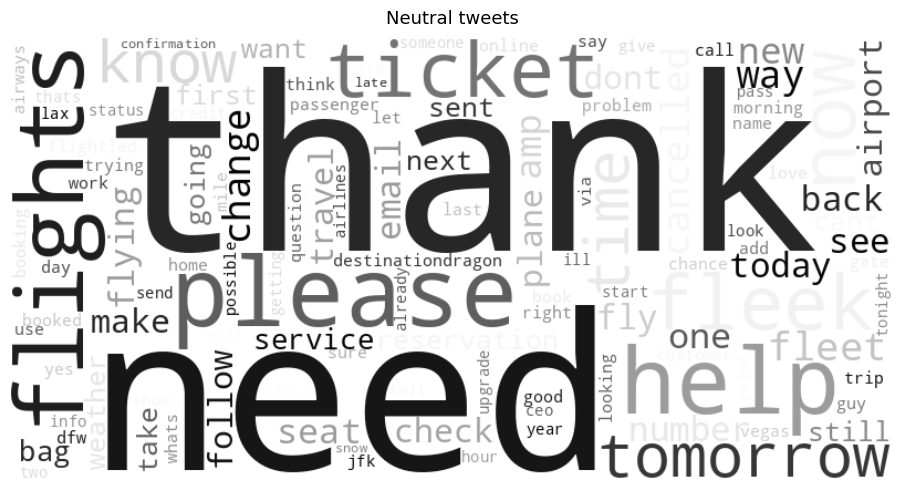

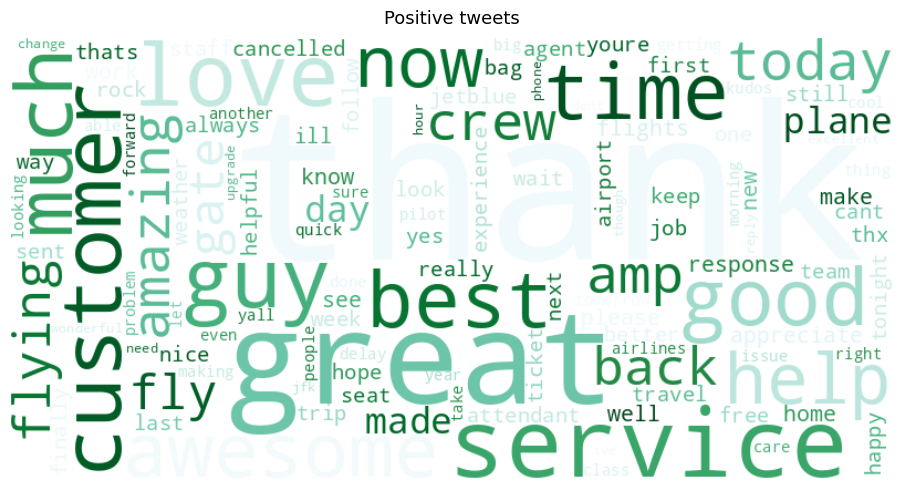

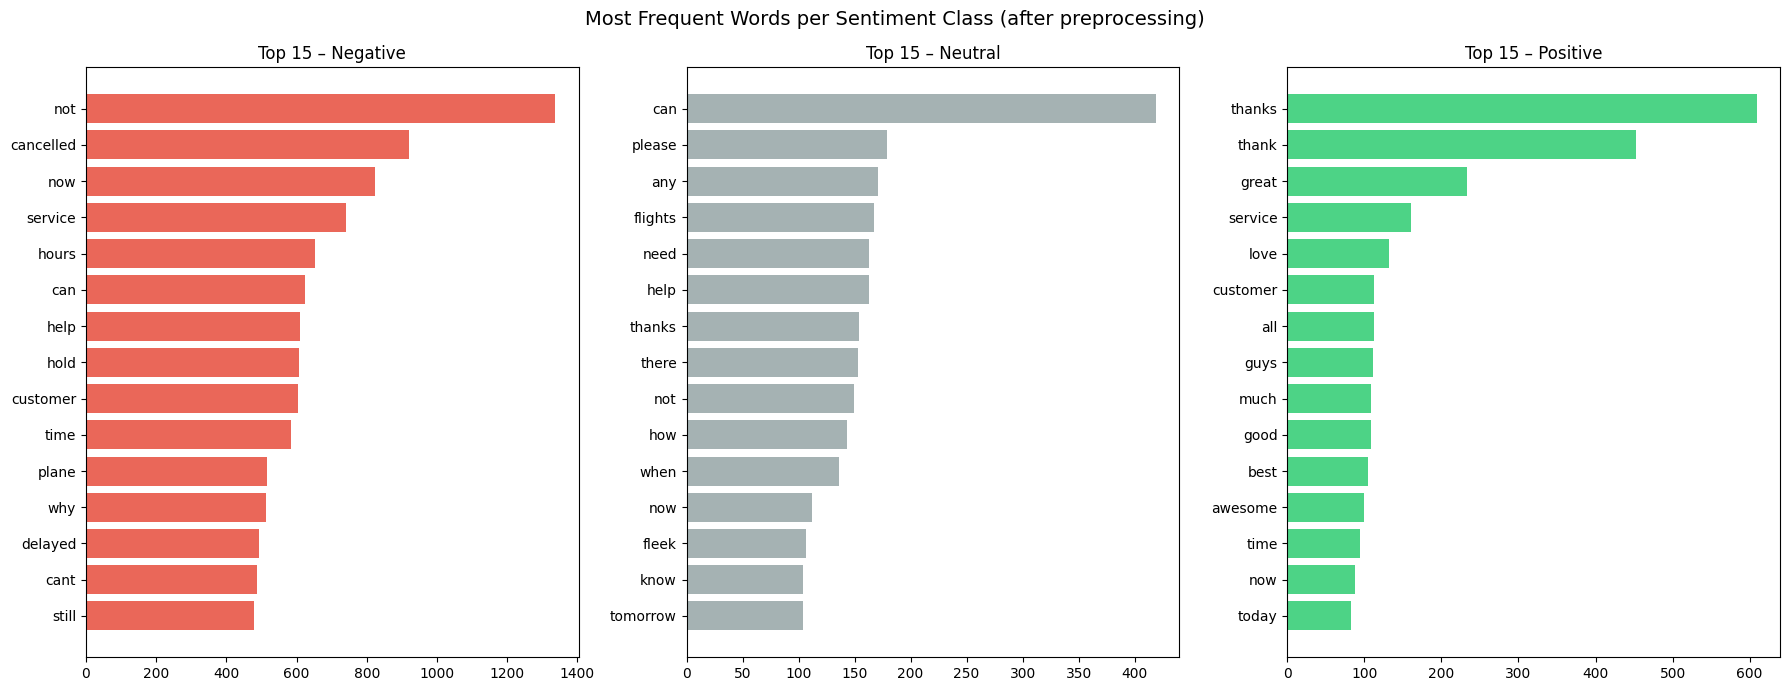

              precision    recall  f1-score   support

    negative       0.77      0.96      0.85      1835
     neutral       0.71      0.38      0.50       620
    positive       0.79      0.53      0.64       473

    accuracy                           0.77      2928
   macro avg       0.76      0.62      0.66      2928
weighted avg       0.76      0.77      0.74      2928



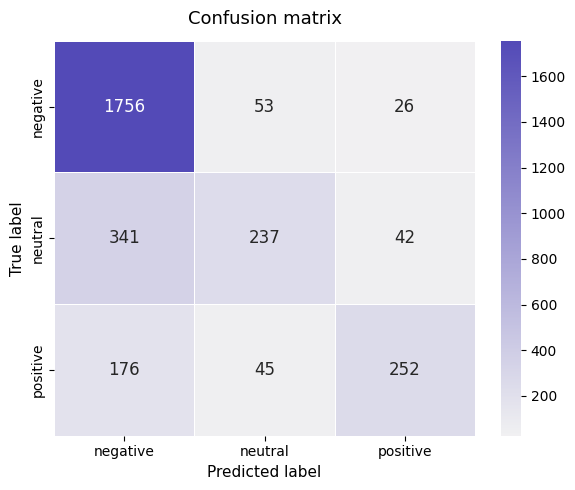

In [ ]:
# =========================
# 1. IMPORT LIBRARIES
# =========================
from google.colab import files
uploaded = files.upload()
import pandas as pd
import numpy as np
import re
import math
from collections import defaultdict, Counter

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support
)

# =========================
# COLOR PALETTE
# =========================
COLORS = {
    'negative': "#FD6532",   # coral-400
    'neutral':  "#A9A792",   # gray-400
    'positive': "#01AF78",   # teal-400
}
PALETTE = [COLORS['negative'], COLORS['neutral'], COLORS['positive']]

# Accent colors for supporting charts
ACCENT_PURPLE = '#534AB7'
ACCENT_BLUE   = '#185FA5'
ACCENT_AMBER  = '#BA7517'

# Light fills for confusion matrix / heatmap backgrounds
FILLS = {
    'negative': '#FAECE7',   # coral-50
    'neutral':  '#F1EFE8',   # gray-50
    'positive': '#E1F5EE',   # teal-50
}

# =========================
# 2. LOAD DATA
# =========================
df = pd.read_csv('Tweets.csv')

print(df.shape)
print(df.dtypes)
print(df.head())
print(df.isnull().sum())

# =========================
# 3. DATA CLEANING
# =========================
cols_to_drop = [
    'tweet_id', 'tweet_location', 'user_timezone',
    'negativereason_confidence', 'airline_sentiment_confidence'
]
df.drop(columns=cols_to_drop, inplace=True)

# =========================
# 4. PREPROCESSING
# =========================
STOPWORDS = {
    'i','me','my','myself','we','our','ours','ourselves','you',
    'your','yours','yourself','he','him','his','himself','she',
    'her','hers','herself','it','its','itself','they','them',
    'their','theirs','themselves','what','which','who','whom',
    'this','that','these','those','am','is','are','was','were',
    'be','been','being','have','has','had','having','do','does',
    'did','doing','a','an','the','and','but','if','or','because',
    'as','until','while','of','at','by','for','with','about',
    'against','between','into','through','to','from','up','down',
    'in','out','on','off','over','then','once','just','so',
    'flight','airline','united','american','southwest','delta',
    'usairways','virginamerica','get','got','will','would','could'
}

def preprocess(text):
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = text.lower()
    tokens = text.split()
    tokens = [t for t in tokens if t not in STOPWORDS and len(t) > 2]
    return tokens

df['tokens'] = df['text'].apply(preprocess)

# =========================
# 5. ENCODE TARGET
# =========================
label_map = {'negative': 0, 'neutral': 1, 'positive': 2}
df['label'] = df['airline_sentiment'].map(label_map)

print(df['label'].value_counts())

# =========================
# 6. TRAIN-TEST SPLIT
# =========================
train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df['label']
)

# =========================
# 7. EDA VISUALIZATION
# =========================
sentiment_counts = df['airline_sentiment'].value_counts()
ordered_labels = ['negative', 'neutral', 'positive']
ordered_counts = [sentiment_counts.get(l, 0) for l in ordered_labels]
ordered_colors = [COLORS[l] for l in ordered_labels]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor('white')

# Bar chart
bars = axes[0].bar(ordered_labels, ordered_counts, color=ordered_colors, width=0.55, edgecolor='white', linewidth=1.2)
axes[0].set_title('Tweet count by sentiment', fontsize=13, fontweight='normal', pad=12)
axes[0].set_xlabel('')
axes[0].set_ylabel('Count', fontsize=11)
axes[0].spines[['top', 'right']].set_visible(False)
axes[0].tick_params(axis='both', labelsize=10)
for bar, count in zip(bars, ordered_counts):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 40,
        f'{count:,}', ha='center', va='bottom', fontsize=10, color='#444441'
    )

# Pie chart
wedge_props = dict(linewidth=2, edgecolor='white')
axes[1].pie(
    ordered_counts,
    labels=ordered_labels,
    colors=ordered_colors,
    autopct='%1.1f%%',
    startangle=140,
    wedgeprops=wedge_props,
    textprops={'fontsize': 10}
)
axes[1].set_title('Sentiment distribution', fontsize=13, fontweight='normal', pad=12)

plt.tight_layout()

plt.show()
# Negative reason breakdown
neg_df = df[df['airline_sentiment'] == 'negative']
reason_counts = neg_df['negativereason'].value_counts().dropna()
print(reason_counts)

# Bar chart
plt.figure(figsize=(12, 6))
reason_counts.plot(kind='barh', color='#C0392B')
plt.title('Negative Reason Frequency'); plt.xlabel('Count')
plt.gca().invert_yaxis(); plt.tight_layout()
plt.savefig('fig4_neg_reasons.png', dpi=150); plt.show()
# Sentiment by airline
airline_sent = df.groupby(['airline','airline_sentiment']).size().unstack(fill_value=0)
print(airline_sent)

# Stacked percentage chart
airline_pct = airline_sent.div(airline_sent.sum(axis=1), axis=0) * 100
airline_pct.plot(kind='bar', stacked=True, figsize=(12, 6),
                 color=['#E74C3C','#95A5A6','#2ECC71'])
plt.title('Relative Sentiment Share per Airline (%)')
plt.xlabel('Airline'); plt.ylabel('Percentage (%)')
plt.xticks(rotation=30); plt.legend(title='Sentiment'); plt.tight_layout()
plt.savefig('fig3_airline_pct.png', dpi=150); plt.show()
# =========================
# 8. WORDCLOUD
# =========================
WC_COLORMAPS = {
    0: 'YlOrRd',   # negative — warm reds/oranges
    1: 'Greys',    # neutral  — gray scale
    2: 'BuGn',     # positive — blue-greens
}
WC_TITLES = {0: 'Negative tweets', 1: 'Neutral tweets', 2: 'Positive tweets'}

def generate_wordcloud(texts, label_id):
    all_tokens = ' '.join([' '.join(t) for t in texts])
    wc = WordCloud(
        width=800, height=400,
        background_color='white',
        colormap=WC_COLORMAPS[label_id],
        max_words=120,
        collocations=False
    ).generate(all_tokens)
    plt.figure(figsize=(10, 5))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(WC_TITLES[label_id], fontsize=13, fontweight='normal', pad=10)
    plt.tight_layout()
    plt.show()

for label_id in [0, 1, 2]:
    generate_wordcloud(df[df['label'] == label_id]['tokens'], label_id)

#Top-15 Words per Sentiment Class
from collections import Counter

def top_words(label, n=15):
    tokens = df[df['airline_sentiment'] == label]['tokens']
    flat   = [t for sublist in tokens for t in sublist]
    return Counter(flat).most_common(n)

top_neg = top_words('negative')
top_neu = top_words('neutral')
top_pos = top_words('positive')

# Plot comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, data, title, color in zip(axes,
        [top_neg, top_neu, top_pos],
        ['Negative','Neutral','Positive'],
        ['#E74C3C','#95A5A6','#2ECC71']):
    words, counts = zip(*data)
    ax.barh(range(len(words)), counts, color=color, alpha=0.85)
    ax.set_yticks(range(len(words)))
    ax.set_yticklabels(words); ax.invert_yaxis()
    ax.set_title(f'Top 15 – {title}')
plt.suptitle('Most Frequent Words per Sentiment Class (after preprocessing)', fontsize=14)
plt.tight_layout()
plt.savefig('fig12_top_words.png', dpi=150); plt.show()

# =========================
# 9. BUILD VOCABULARY
# =========================
def build_vocab(tokens_list):
    vocab = set()
    for tokens in tokens_list:
        vocab.update(tokens)
    return sorted(vocab)

vocab = build_vocab(train_df['tokens'])

# =========================
# 10. NAIVE BAYES MODEL
# =========================
class MultinomialNaiveBayes:
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X_tokens, y, vocab):
        self.classes = sorted(y.unique())
        self.vocab = vocab
        V = len(vocab)

        self.log_prior = {}
        self.log_likelihood = {}

        for c in self.classes:
            class_tokens = [
                token for tokens, label in zip(X_tokens, y)
                if label == c for token in tokens
            ]

            N_c = len(class_tokens)
            self.log_prior[c] = math.log(sum(y == c) / len(y))

            counts = defaultdict(int)
            for token in class_tokens:
                counts[token] += 1

            denom = math.log(N_c + self.alpha * V)

            self.log_likelihood[c] = {
                word: math.log(counts.get(word, 0) + self.alpha) - denom
                for word in vocab
            }

    def predict(self, X_tokens):
        predictions = []
        for tokens in X_tokens:
            scores = {}
            for c in self.classes:
                score = self.log_prior[c]
                score += sum(self.log_likelihood[c].get(t, 0) for t in tokens)
                scores[c] = score
            predictions.append(max(scores, key=scores.get))
        return predictions

# =========================
# 11. TRAIN & PREDICT
# =========================
nb = MultinomialNaiveBayes()
nb.fit(train_df['tokens'], train_df['label'], vocab)

y_pred = nb.predict(test_df['tokens'])
y_true = test_df['label']

# =========================
# 12. EVALUATION — CONFUSION MATRIX
# =========================
label_names = ['negative', 'neutral', 'positive']

print(classification_report(y_true, y_pred, target_names=label_names))

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
fig.patch.set_facecolor('white')

# Custom heatmap using seaborn for full color control
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap=sns.light_palette(ACCENT_PURPLE, as_cmap=True),
    xticklabels=label_names,
    yticklabels=label_names,
    linewidths=0.5,
    linecolor='white',
    ax=ax,
    annot_kws={'size': 12, 'weight': 'normal'}
)
ax.set_title('Confusion matrix', fontsize=13, fontweight='normal', pad=12)
ax.set_xlabel('Predicted label', fontsize=11)
ax.set_ylabel('True label', fontsize=11)
ax.tick_params(axis='both', labelsize=10)
plt.tight_layout()
plt.show()
